In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from IPython.display import display

In [2]:
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "dataset").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "dataset").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Dataset folder not found. Open the Brain-Tumor-AI project."
    )

DATASET_PATH = PROJECT_ROOT / "dataset"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "valid", "test"]
CLASSES = ["glioma", "meningioma", "no_tumor", "pituitary"]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

CLASS_LABELS = {
    "glioma": "Glioma",
    "meningioma": "Meningioma",
    "no_tumor": "No Tumor",
    "pituitary": "Pituitary"
}

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATASET_PATH)
print("Reports path:", REPORTS_DIR)
print("Dataset exists:", DATASET_PATH.exists())
print("Classes:", CLASSES)

Project root: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI
Dataset path: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\dataset
Reports path: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\reports
Dataset exists: True
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [3]:

structure_errors = []

for split in SPLITS:
    split_path = DATASET_PATH / split

    if not split_path.is_dir():
        structure_errors.append(f"Missing split: {split}")
        continue

    for class_name in CLASSES:
        class_path = split_path / class_name

        if not class_path.is_dir():
            structure_errors.append(
                f"Missing folder: {split}/{class_name}"
            )

if structure_errors:
    print("DATASET STRUCTURE ISSUES:")
    for error in structure_errors:
        print("-", error)
else:
    print("Dataset structure validated successfully.")

print("\nFolder structure:")
for split in SPLITS:
    print(f"\n{split}/")
    for class_name in CLASSES:
        print(f"  {class_name}/")


Dataset structure validated successfully.

Folder structure:

train/
  glioma/
  meningioma/
  no_tumor/
  pituitary/

valid/
  glioma/
  meningioma/
  no_tumor/
  pituitary/

test/
  glioma/
  meningioma/
  no_tumor/
  pituitary/


In [4]:

records = []

for split in SPLITS:
    for class_name in CLASSES:
        class_path = DATASET_PATH / split / class_name

        if not class_path.is_dir():
            continue

        image_files = sorted(
            path for path in class_path.iterdir()
            if path.is_file()
            and path.suffix.lower() in IMAGE_EXTENSIONS
        )

        records.append({
            "split": split,
            "class": class_name,
            "class_label": CLASS_LABELS[class_name],
            "image_count": len(image_files)
        })

summary_df = pd.DataFrame(records)

summary_table = summary_df.pivot(
    index="class_label",
    columns="split",
    values="image_count"
).reindex(CLASS_LABELS.values())

summary_table["total"] = summary_table.sum(axis=1)

print("IMAGE COUNT SUMMARY")
display(summary_table.fillna(0).astype(int))

print("\nTOTALS BY SPLIT")
display(
    summary_df.groupby("split")["image_count"]
    .sum()
    .reindex(SPLITS)
    .rename("total_images")
    .to_frame()
)

print("\nTOTAL IMAGES:", int(summary_df["image_count"].sum()))

summary_df.to_csv(
    REPORTS_DIR / "dataset_class_summary.csv",
    index=False
)

print("Saved: reports/dataset_class_summary.csv")


IMAGE COUNT SUMMARY


split,test,train,valid,total
class_label,,,,
Glioma,80,564,161,805
Meningioma,63,358,124,545
No Tumor,49,335,99,483
Pituitary,54,438,118,610



TOTALS BY SPLIT


,total_images
split,
train,1695
valid,502
test,246



TOTAL IMAGES: 2443
Saved: reports/dataset_class_summary.csv


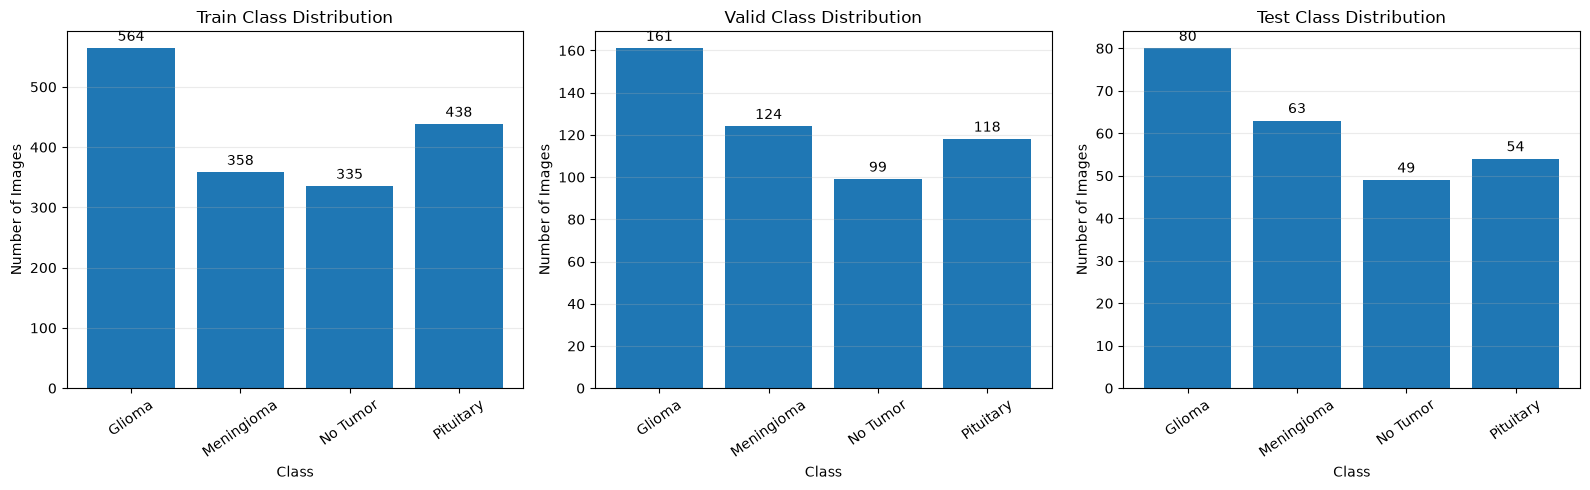

Saved: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\reports\figures\class_distribution.png


In [5]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, split in zip(axes, SPLITS):
    data = (
        summary_df[summary_df["split"] == split]
        .set_index("class_label")
        .reindex(CLASS_LABELS.values())
    )

    bars = ax.bar(data.index, data["image_count"])

    ax.set_title(f"{split.title()} Class Distribution")
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of Images")
    ax.tick_params(axis="x", rotation=35)
    ax.bar_label(bars, padding=3)
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

chart_path = FIGURES_DIR / "class_distribution.png"
fig.savefig(chart_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", chart_path)


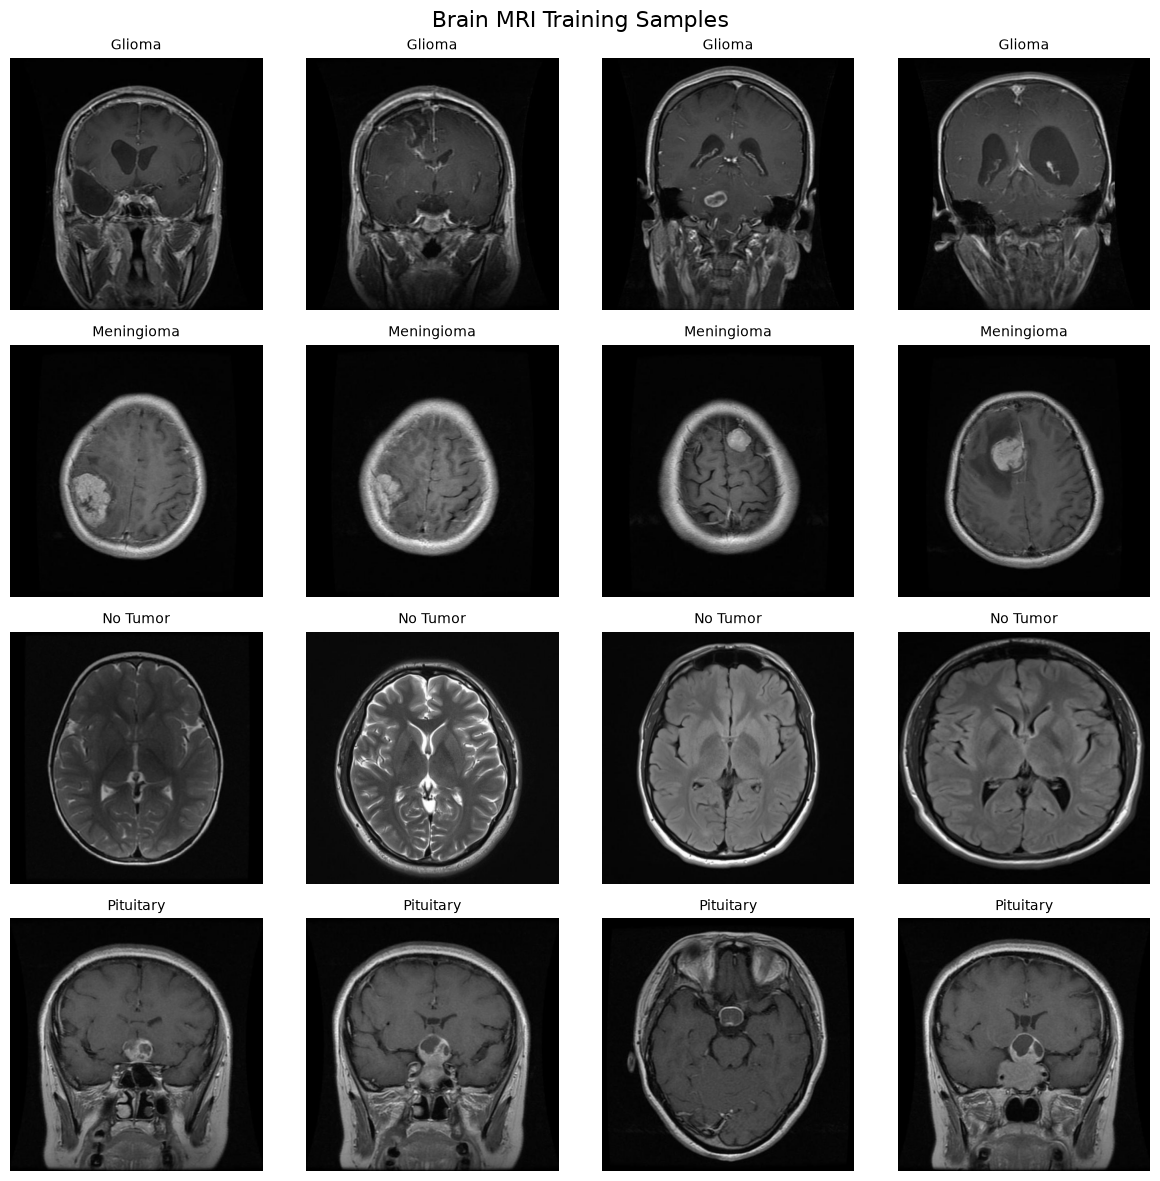

Saved: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\reports\figures\sample_mri_images.png


In [6]:

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for row, class_name in enumerate(CLASSES):
    class_path = DATASET_PATH / "train" / class_name

    image_files = sorted(
        path for path in class_path.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    )

    # Deterministic samples for reproducibility
    sample_files = image_files[:4]

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col < len(sample_files):
            with Image.open(sample_files[col]) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(
                CLASS_LABELS[class_name],
                fontsize=10
            )

fig.suptitle("Brain MRI Training Samples", fontsize=16)
fig.tight_layout()

sample_path = FIGURES_DIR / "sample_mri_images.png"
fig.savefig(sample_path, dpi=120, bbox_inches="tight")
plt.show()

print("Saved:", sample_path)


In [7]:

image_modes = Counter()
image_dimensions = Counter()
corrupted_files = []
image_count_checked = 0

for split in SPLITS:
    for class_name in CLASSES:
        class_path = DATASET_PATH / split / class_name

        if not class_path.is_dir():
            continue

        for path in class_path.iterdir():
            if (
                not path.is_file()
                or path.suffix.lower() not in IMAGE_EXTENSIONS
            ):
                continue

            try:
                with Image.open(path) as img:
                    img.verify()

                # Reopen after verify to inspect metadata
                with Image.open(path) as img:
                    image_modes[img.mode] += 1
                    image_dimensions[img.size] += 1

                image_count_checked += 1

            except (OSError, ValueError, UnidentifiedImageError) as exc:
                corrupted_files.append({
                    "path": str(path.relative_to(PROJECT_ROOT)),
                    "error": str(exc)
                })

print("Images checked:", image_count_checked)
print("Image modes:", dict(image_modes))
print("Image dimensions:", dict(image_dimensions))
print("Corrupted images:", len(corrupted_files))

if corrupted_files:
    display(pd.DataFrame(corrupted_files))
    pd.DataFrame(corrupted_files).to_csv(
        REPORTS_DIR / "corrupted_images.csv",
        index=False
    )
else:
    print("All supported image files passed verification.")


Images checked: 2443
Image modes: {'RGB': 2443}
Image dimensions: {(640, 640): 2443}
Corrupted images: 0
All supported image files passed verification.


In [9]:

train_counts = (
    summary_df[summary_df["split"] == "train"]
    .set_index("class")
    .reindex(CLASSES)["image_count"]
)

train_percentages = (
    train_counts / train_counts.sum() * 100
).round(2)

imbalance_df = pd.DataFrame({
    "class": CLASSES,
    "training_images": train_counts.values,
    "percentage": train_percentages.values
})

print("TRAINING CLASS BALANCE")
display(imbalance_df)

imbalance_ratio = (
    train_counts.max() / train_counts.min()
    if train_counts.min() > 0 else np.inf
)

print(f"Largest-to-smallest class ratio: {imbalance_ratio:.2f}:1")


TRAINING CLASS BALANCE


,class,training_images,percentage
0,glioma,564,33.27
1,meningioma,358,21.12
2,no_tumor,335,19.76
3,pituitary,438,25.84


Largest-to-smallest class ratio: 1.68:1


In [10]:

total_images = int(summary_df["image_count"].sum())
split_totals = summary_df.groupby("split")["image_count"].sum()


print("BRAIN TUMOR MRI — DATASET ANALYSIS REPORT")


print(f"Total images: {total_images}")
print(f"Classes: {len(CLASSES)}")
print(f"Images checked: {image_count_checked}")
print(f"Corrupted images: {len(corrupted_files)}")
print(f"Image modes: {dict(image_modes)}")
print(f"Image dimensions: {dict(image_dimensions)}")

for split in SPLITS:
    print(f"{split.title()} images: {int(split_totals.get(split, 0))}")

print("\nGenerated reports:")
print("- reports/dataset_class_summary.csv")
print("- reports/figures/class_distribution.png")
print("- reports/figures/sample_mri_images.png")

if total_images == 2443 and len(corrupted_files) == 0:
    print("\nDataset checks match the expected image count.")
else:
    print("\nReview the counts and any image errors above.")



BRAIN TUMOR MRI — DATASET ANALYSIS REPORT
Total images: 2443
Classes: 4
Images checked: 2443
Corrupted images: 0
Image modes: {'RGB': 2443}
Image dimensions: {(640, 640): 2443}
Train images: 1695
Valid images: 502
Test images: 246

Generated reports:
- reports/dataset_class_summary.csv
- reports/figures/class_distribution.png
- reports/figures/sample_mri_images.png

Dataset checks match the expected image count.
